Load data

In [15]:
import numpy as np
import pandas as pd

# Loading SC data
connectomes = np.load("./data/Structural_Connectomes.npz")
sc = connectomes['SC']
sc_d = connectomes['SC_D']

# Loading fmri data
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
flp = fmri['flp']
fhi = fmri['fhi']
ts_ap = fmri['ts_ap']
ts_hc = fmri['ts_hc']
ts_nap = fmri['ts_nap']

# Loading clinical scores data
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]
ymrs_AP = clinical["ymrs_AP"]
ymrs_NAP = clinical["ymrs_NAP"]

Hopf

In [2]:
import numpy as np
import scipy.linalg as la

def hopf_int(Cnew, f_diff, sigma):
    """
    Linearized Hopf oscillator (Stuart-Landau) model solver.
    
    Parameters:
    Cnew   : ndarray (N, N) - Generative Effective Connectivity matrix
    f_diff : ndarray (N,)   - Intrinsic node frequencies (omega)
    sigma  : float          - Noise standard deviation
    
    Returns:
    FCsim  : ndarray (N, N) - Simulated Functional Connectivity (normalized correlation)
    COVsim : ndarray (2N, 2N)- Full stationary covariance matrix (K)
    aux    : None           - Auxiliary placeholder
    A      : ndarray (2N, 2N)- The full system Jacobian (J)
    """
    N = Cnew.shape[0]
    
    # 1. Set the bifurcation parameter 'a' near criticality
    # Proximity to zero allows the linear approximation [cite: 572, 578]
    a = -0.02 
    
    # 2. Calculate the strength S (row sums of connectivity)
    # This accounts for the coupling term g*sum(Cjk*(zk - zj)) [cite: 565]
    S = np.sum(Cnew, axis=1)
    
    # 3. Construct the Jacobian sub-blocks [cite: 581, 583]
    # Jxx = Jyy = diag(a - S) + C
    Jxx = np.diag(a - S) + Cnew
    
    # Jxy = -Jyx = diag(omega)
    # f_diff represents the intrinsic frequencies estimated from data 
    Jxy = np.diag(f_diff)
    
    # 4. Assemble the full 2N x 2N Jacobian matrix (J) [cite: 581]
    # Structure: [[Jxx, Jxy], [Jyx, Jyy]]
    A = np.block([
        [Jxx,  Jxy],
        [-Jxy, Jxx]
    ])
    
    # 5. Define the noise covariance matrix Q
    # Based on additive uncorrelated Gaussian noise with variance sigma^2 
    Q = (sigma**2) * np.eye(2 * N) # diagonal is sigma**2
    
    # 6. Solve the Lyapunov equation for stationary covariance K 
    # J*K + K*J^T + Q = 0
    # In scipy, solve_continuous_lyapunov solves: AX + XA^H = Q
    # We pass -Q because the standard form is J*K + K*J^T = -Q
    COVsim = la.solve_continuous_lyapunov(A, -Q)
    
    # 7. Extract the real part covariance (BOLD signal) 
    # This is the top-left N x N block of K
    real_cov = COVsim[:N, :N]
    
    # 8. Normalize the covariance to get the FC correlation matrix
    d = np.diag(real_cov).copy()
    # Avoid division by zero
    d[d <= 0] = 1e-12
    std_inv = 1.0 / np.sqrt(d)
    FCsim = real_cov * np.outer(std_inv, std_inv)
    
    return FCsim, COVsim, None, A

Omega

In [3]:
from scipy.signal import welch

def estimate_intrinsic_frequencies(ts, TR, band=(0.008, 0.08)):
    """
    Estimates the peak frequency for each brain region within a specific band.
    
    Parameters:
    ts   : ndarray (Regions, Timepoints)
    TR   : float - Repetition time in seconds
    band : tuple - The frequency range (low, high) in Hz
    
    Returns:
    f_diff : ndarray (Regions,) - The peak frequency for each region in Hz
    """
    N, T = ts.shape
    fs = 1.0 / TR  # Sampling frequency
    f_diff = np.zeros(N)
    
    # We use Welch's method to estimate the Power Spectral Density (PSD)
    # nperseg should be large enough to capture the low frequencies
    freqs, psd = welch(ts, fs=fs, nperseg=min(T, 512))
    # OBS: Welch’s method works by breaking the time series into overlapping segments, 
    # calculating the power spectrum for each segment, and then averaging them.
    
    # Create a mask for the frequency band of interest (0.008 - 0.08 Hz)
    idx_band = np.where((freqs >= band[0]) & (freqs <= band[1]))[0]
    
    for i in range(N):
        # Find the frequency index with the maximum power within the band
        peak_idx = idx_band[np.argmax(psd[i, idx_band])]
        f_diff[i] = freqs[peak_idx]
        # OBS: By finding the peak of the Welch PSD, you are finding the frequency 
        # that was consistently the most dominant throughout the entire scan, 
        # rather than just a random spike at one moment.
        
    return f_diff



In [9]:
np.shape(ts_hc[0])

(100, 1581)

GEC

In [4]:
import numpy as np
import scipy.linalg as la

def estimate_gec(ts, sc, TR, max_iter=5000):
    """
    Estimates the Generative Effective Connectivity (GEC) using a Linear Hopf model.
    
    This function personalizes a whole-brain dynamical model by adjusting the 
    effective weights of structural connections. It aims to minimize the 
    difference between empirical brain activity and model-simulated dynamics 
    at both zero-lag and a one-TR time shift.

    Parameters:
    -----------
    ts : ndarray (N, T)
        Empirical BOLD time series for a single subject.
    sc : ndarray (N, N)
        Structural Connectivity backbone (the disconnectome mask).
    TR : float
        Repetition time of the fMRI data in seconds.
    max_iter : int, optional
        Maximum iterations for gradient descent (default is 5000).

    Returns:
    --------
    Ceff : ndarray (N, N)
        The optimized Effective Connectivity matrix.
    FCsim : ndarray (N, N)
        The final simulated static functional connectivity matrix.
    FSsim : ndarray (N, N)
        The final simulated time-shifted connectivity matrix.
    fittFC : float
        Pearson correlation between empirical and simulated static FC.
    fittFS : float
        Pearson correlation between empirical and simulated shifted FC.
    """
    N, T = ts.shape
    Tau = 1 
    sigma = 0.01 
    epsFC = 0.0002 
    epsFCtau = 0.00004 
    maxC = 0.1 
    
    tril_idx = np.tril_indices(N, k=-1)
    
    # 1. Prepare Empirical Targets
    ts_c = ts - np.mean(ts, axis=1, keepdims=True)
    FCemp = np.corrcoef(ts)
    COVemp = np.cov(ts, ddof=1)
    
    # Empirical Shifted Covariance normalized to correlation (FSemp)
    COVtauemp_raw = np.dot(ts_c[:, :-Tau], ts_c[:, Tau:].T) / T
    diag_cov = np.diag(COVemp)
    sigratio = 1.0 / np.sqrt(np.outer(diag_cov, diag_cov))
    FSemp = COVtauemp_raw * sigratio

    # Calculate individual intrinsic frequencies (Omega)
    f_diff = estimate_intrinsic_frequencies(ts, TR)

    # 2. Optimization Setup
    Cnew = np.copy(sc)
    olderror = 1e6
    update_mask = (sc > 0) | np.eye(N, k=N//2, dtype=bool)

    # 3. Iterative Optimization Loop
    for iteration in range(1, max_iter + 1):
        # Solve Linear Hopf dynamics
        FCsim_curr, COVsim_full, aux, A = hopf_int(Cnew, f_diff, sigma)
        
        # Propagate covariance forward in time (FSsim)
        matrix_exp = la.expm((Tau * TR) * A)
        COVtausim_raw = matrix_exp @ COVsim_full
        COVtausim_real = COVtausim_raw[:N, :N] 
        
        # Normalize shifted covariance using zero-lag standard deviations
        diag_sim = np.diag(COVsim_full[:N, :N]).copy()
        diag_sim[diag_sim <= 0] = 1e-12 
        sigratiosim = 1.0 / np.sqrt(np.outer(diag_sim, diag_sim))
        FSsim_curr = COVtausim_real * sigratiosim
        
        # Calculate Mean Squared Error (MSE)
        error_FC = np.mean((FCemp - FCsim_curr)**2)
        error_FS = np.mean((FSemp - FSsim_curr)**2)
        
        # Convergence check every 100 iterations
        if iteration % 100 == 0:
            errornow = error_FC + error_FS
            if (olderror - errornow) / errornow < 0.01 or olderror < errornow:
                print(f"Converged at iteration {iteration} | MSE: {errornow:.6f}")
                break
            olderror = errornow

        # Gradient Descent Step
        gradient = epsFC * (FCemp - FCsim_curr) + epsFCtau * (FSemp - FSsim_curr)
        Cnew[update_mask] += gradient[update_mask]
        
        # Enforce non-negativity and global scaling
        Cnew[Cnew < 0] = 0
        if Cnew.max() > 0:
            Cnew = (Cnew / Cnew.max()) #* maxC

    # 4. Final Output Generation
    # Extract results from the final optimized state
    FCsim, COVsim_full, aux, A = hopf_int(Cnew, f_diff, sigma)
    
    # Final shifted matrix calculation
    matrix_exp = la.expm((Tau * TR) * A)
    FSsim_raw = (matrix_exp @ COVsim_full)[:N, :N]
    diag_final = np.diag(COVsim_full[:N, :N]).copy()
    diag_final[diag_final <= 0] = 1e-12
    sig_final = 1.0 / np.sqrt(np.outer(diag_final, diag_final))
    FSsim = FSsim_raw * sig_final
    
    # Calculate final goodness-of-fit (Pearson r)
    fittFC = np.corrcoef(FCemp[tril_idx], FCsim[tril_idx])[0, 1]
    fittFS = np.corrcoef(FSemp[tril_idx], FSsim[tril_idx])[0, 1]
    
    return Cnew, FCsim, FSsim, fittFC, fittFS

FCsim vs FC metrics

In [5]:
import numpy as np
from scipy.stats import pearsonr

def compute_model_metrics(emp, sim, matrix_type="FC"):
    """
    Computes a comprehensive suite of comparison metrics between empirical 
    and simulated connectivity matrices.

    Depending on whether the matrix is Functional Connectivity (FC, symmetric) 
    or Shifted Connectivity (FS, asymmetric), the function handles the 
    data extraction differently to ensure statistical validity.

    Metrics computed:
    - Pearson Correlation (r): Spatial similarity of the patterns.
    - Root Mean Square Error (RMSE): Average magnitude of the prediction error.
    - Euclidean Distance: The geometric distance between the two matrices in N-dimensional space.
    - Mean Absolute Error (MAE): The average linear difference between connections.

    Parameters:
    -----------
    emp : ndarray (N, N)
        The empirical matrix (Static FC or Shifted FS).
    sim : ndarray (N, N)
        The simulated matrix generated by the Hopf model.
    matrix_type : str
        "FC" for symmetric matrices (uses lower triangle) or 
        "FS" for asymmetric/directed matrices (uses all off-diagonal elements).

    Returns:
    --------
    metrics : dict
        A dictionary containing the calculated values.
    """
    N = emp.shape[0]
    
    # 1. Vectorize the matrices based on their symmetry
    if matrix_type.upper() == "FC":
        # For symmetric FC, we only look at the unique connections (lower triangle)
        # to avoid double-counting and ignore the diagonal (which is always 1)
        idx = np.tril_indices(N, k=-1)
        v_emp = emp[idx]
        v_sim = sim[idx]
    else:
        # For asymmetric FS, the direction matters (i->j is different from j->i)
        # We take all elements except the diagonal
        mask = ~np.eye(N, dtype=bool)
        v_emp = emp[mask]
        v_sim = sim[mask]

    # 2. Calculate Similarity Metrics
    # Pearson Correlation: r = cov(X,Y) / (std(X)*std(Y))
    r_val, _ = pearsonr(v_emp, v_sim)
    
    # 3. Calculate Distance/Error Metrics
    # RMSE: sqrt( mean( (emp - sim)^2 ) )
    rmse = np.sqrt(np.mean((v_emp - v_sim)**2))
    
    # MAE: mean( |emp - sim| )
    mae = np.mean(np.abs(v_emp - v_sim))
    
    # Euclidean (Frobenius) Distance: sqrt( sum( (emp - sim)^2 ) )
    euclidean = np.linalg.norm(v_emp - v_sim)
    
    # 4. Specific Directedness Metric (Only for FS)
    directedness_sim = None
    if matrix_type.upper() == "FS":
        # Measures how asymmetric the information flow is: ||FS - FS.T||
        directedness_sim = np.linalg.norm(sim - sim.T)

    return {
        "Pearson_r": r_val,
        "RMSE": rmse,
        "MAE": mae,
        "Euclidean_Dist": euclidean,
        "Directedness_Index": directedness_sim
    }

In [58]:
len(ts_nap)

76

In [59]:
import numpy as np
import pandas as pd

# Define exactly how many subjects you want per class
# Example: 15 HC for a strong baseline, 10 AP for primary study, 5 NAP for comparison
n_subjects_config = {
    'HC': 10,
    'AP': 10,
    'NAP': 10
}

TR_value = 2.0
study_results = {group: {} for group in n_subjects_config.keys()}

print("Starting Group-Wise Precision Modeling...")

for group_name, n_to_process in n_subjects_config.items():
    print(f"\n{'='*40}")
    print(f"GROUP: {group_name} | Target: {n_to_process} subjects")
    print(f"{'='*40}")
    
    # Get the list of time series for this group
    # (Assuming ts_hc, ts_ap, ts_nap are already loaded)
    ts_list = ts_hc if group_name == 'HC' else ts_ap if group_name == 'AP' else ts_nap
    
    for i in range(min(n_to_process, len(ts_list))):
        print(f"  [Subject {i+1}/{n_to_process}] Running GEC Optimization...")
        
        # 1. Run GEC Estimation
        # Returns: Ceff, FCsim, FSsim, fittFC, fittFS
        subject_ts = ts_list[i]
        gec, fc_sim, fs_sim, r_fc, r_fs = estimate_gec(subject_ts, sc, TR=TR_value)
        
        # 2. Reconstruct Empirical Targets for distance/error metrics
        ts_c = subject_ts - np.mean(subject_ts, axis=1, keepdims=True)
        fc_emp = np.corrcoef(subject_ts)
        
        # Calculate empirical FS (Time-shifted correlation)
        cov_tau_raw = np.dot(ts_c[:, :-1], ts_c[:, 1:].T) / subject_ts.shape[1]
        diag_cov = np.diag(np.cov(subject_ts))
        sig_inv = 1.0 / np.sqrt(np.outer(diag_cov, diag_cov))
        fs_emp = cov_tau_raw * sig_inv

        # 3. Compute Comprehensive Metrics
        metrics_fc = compute_model_metrics(fc_emp, fc_sim, matrix_type="FC")
        metrics_fs = compute_model_metrics(fs_emp, fs_sim, matrix_type="FS")
        
        # 4. Store results in our nested dictionary
        study_results[group_name][i] = {
            "GEC_matrix": gec,
            "FC_sim": fc_sim,
            "FS_sim": fs_sim,
            "metrics_static": metrics_fc,
            "metrics_shifted": metrics_fs
        }

print("All groups processed successfully.")

Starting Group-Wise Precision Modeling...

GROUP: HC | Target: 10 subjects
  [Subject 1/10] Running GEC Optimization...
Converged at iteration 800 | MSE: 0.067528
  [Subject 2/10] Running GEC Optimization...
Converged at iteration 400 | MSE: 0.111463
  [Subject 3/10] Running GEC Optimization...
Converged at iteration 400 | MSE: 0.106588
  [Subject 4/10] Running GEC Optimization...
Converged at iteration 200 | MSE: 0.153590
  [Subject 5/10] Running GEC Optimization...
Converged at iteration 400 | MSE: 0.096221
  [Subject 6/10] Running GEC Optimization...
Converged at iteration 400 | MSE: 0.124589
  [Subject 7/10] Running GEC Optimization...
Converged at iteration 1000 | MSE: 0.054560
  [Subject 8/10] Running GEC Optimization...
Converged at iteration 300 | MSE: 0.148821
  [Subject 9/10] Running GEC Optimization...
Converged at iteration 800 | MSE: 0.047778
  [Subject 10/10] Running GEC Optimization...
Converged at iteration 300 | MSE: 0.114207

GROUP: AP | Target: 10 subjects
  [Subject

In [60]:
np.save("./data/gec_results.npy", study_results)

print("Results saved to ./data/gec_results.npy")

Results saved to ./data/gec_results.npy


In [6]:
import pickle
study_results = np.load("./data/gec_results.npy", allow_pickle=True).item()

In [9]:
all_metrics = []

for group, subjects in study_results.items():
    for sub_id, data in subjects.items():
        # Flatten the dictionary for this subject
        row = {
            "Group": group,
            "Subject_ID": sub_id,
            "FC_Pearson_r": data["metrics_static"]["Pearson_r"],
            "FC_RMSE": data["metrics_static"]["RMSE"],
            "FS_Pearson_r": data["metrics_shifted"]["Pearson_r"],
            "FS_Directedness": data["metrics_shifted"]["Directedness_Index"],
            "FS_Euclidean": data["metrics_shifted"]["Euclidean_Dist"]
        }
        all_metrics.append(row)

# Create the summary table
df_results = pd.DataFrame(all_metrics)

df_results 

,Group,Subject_ID,FC_Pearson_r,FC_RMSE,FS_Pearson_r,FS_Directedness,FS_Euclidean
0,HC,0,0.759184,0.177176,0.694005,0.204696,18.460597
1,HC,1,0.758123,0.232703,0.698692,0.067373,23.436967
2,HC,2,0.745225,0.228262,0.691018,0.058295,22.832922
3,HC,3,0.826796,0.278040,0.813634,0.048599,27.372924
4,HC,4,0.767408,0.215805,0.705319,0.039121,21.710096
5,HC,5,0.772818,0.247029,0.723328,0.040286,24.749044
6,HC,6,0.828471,0.158049,0.786772,0.155339,16.752131
7,HC,7,0.816690,0.271513,0.782246,0.066599,27.031449
8,HC,8,0.747855,0.148348,0.690344,0.086738,15.396509
9,HC,9,0.755440,0.236613,0.716678,0.030390,23.654379


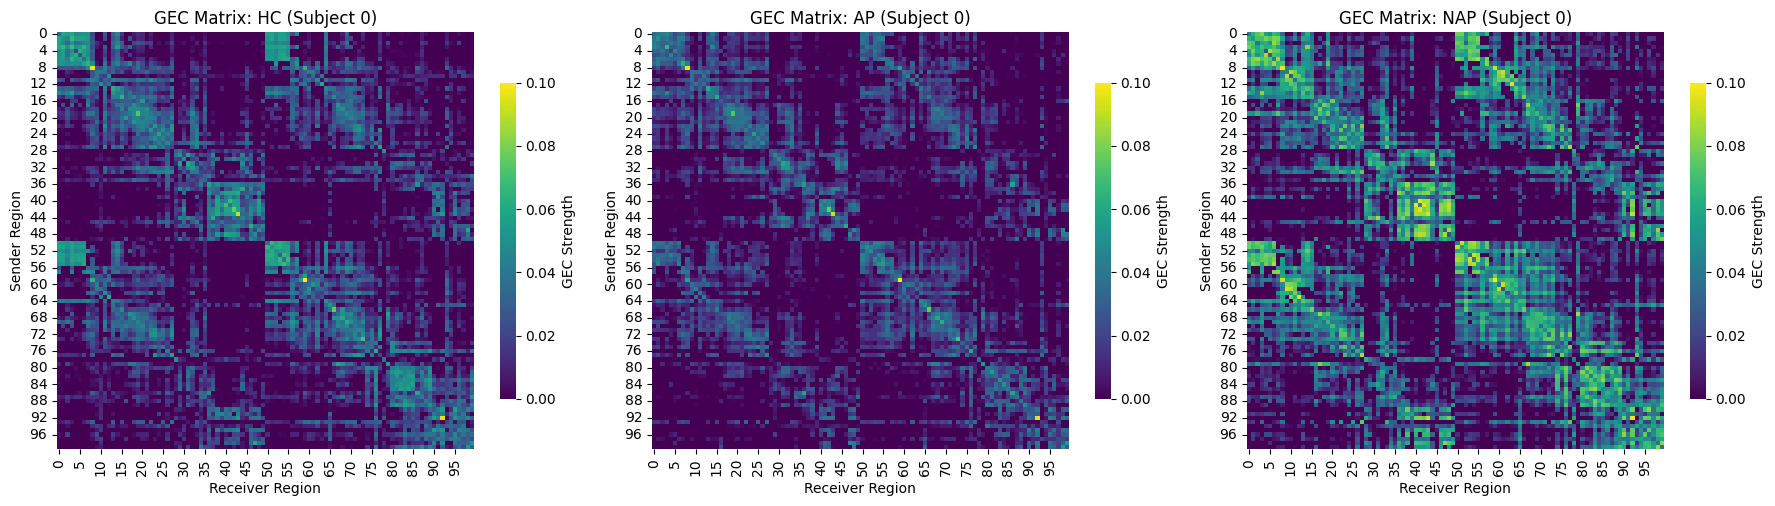

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# We'll plot Subject 0 for each group to see the "representative" connectivity
target_subjects = ['HC', 'AP', 'NAP']
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, group_name in enumerate(target_subjects):
    # Extract the GEC matrix for the first subject (0) of this group
    # study_results[group_name][0] contains the data for that subject
    matrix = study_results[group_name][1]["GEC_matrix"]
    
    sns.heatmap(matrix, ax=axes[i], cmap='viridis', square=True, 
                vmin=0, vmax=0.1, cbar_kws={'shrink': .7, 'label': 'GEC Strength'})
    
    axes[i].set_title(f'GEC Matrix: {group_name} (Subject 0)')
    axes[i].set_xlabel('Receiver Region')
    axes[i].set_ylabel('Sender Region')

plt.tight_layout()
plt.show()

Asymmetry study

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Storage for asymmetry matrices and global indices
asym_results = {group: [] for group in study_results.keys()}
global_asym_index = {group: [] for group in study_results.keys()}

for group, subjects in study_results.items():
    for sub_id, data in subjects.items():
        C = data["GEC_matrix"]
        
        # Define Asymmetry as requested: (C - C.T) / 2
        C_asym = (C - C.T) / 2
        
        asym_results[group].append(C_asym)
        
        # Global Asymmetry Index: The Frobenius norm of the asymmetric part
        # This tells us the total 'strength' of directed flow in that brain
        index = np.linalg.norm(C_asym, ord='fro')
        global_asym_index[group].append(index)

print("Asymmetry matrices and global indices computed.")

Asymmetry matrices and global indices computed.


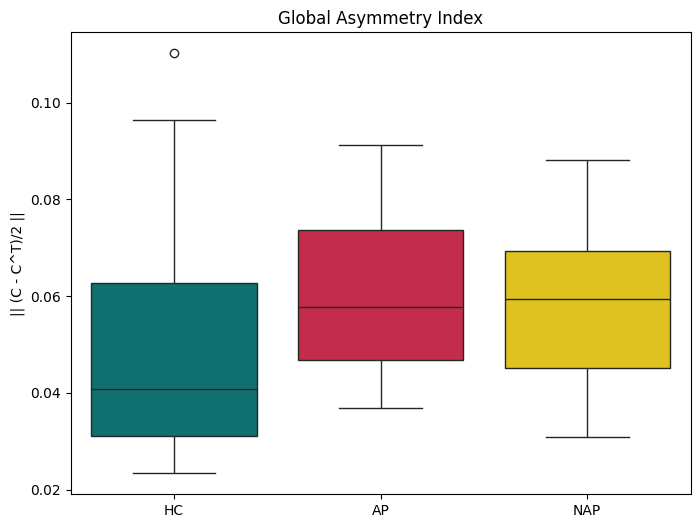

Mean Global Asymmetry for HC: 0.0524
Mean Global Asymmetry for AP: 0.0607
Mean Global Asymmetry for NAP: 0.0580


In [64]:
plt.figure(figsize=(8, 6))
data_to_plot = [global_asym_index['HC'], global_asym_index['AP'], global_asym_index['NAP']]
sns.boxplot(data=data_to_plot, palette=['teal', 'crimson', 'gold'])
plt.xticks([0, 1, 2], ['HC', 'AP', 'NAP'])
plt.title("Global Asymmetry Index")
plt.ylabel("|| (C - C^T)/2 ||")
plt.show()

# Print mean values
for group in global_asym_index:
    print(f"Mean Global Asymmetry for {group}: {np.mean(global_asym_index[group]):.4f}")

Perturbability

In [10]:
def calculate_group_mean_fc(ts_list):
    """
    Calculates the group-average Functional Connectivity (FC) matrix.

    The FC for each subject is computed as the Pearson correlation matrix
    of their time series. The group mean is the element-wise average 
    across all subjects in the group.

    Parameters:
    -----------
    ts_list : list of ndarray
        A list where each element is a (Regions, Timepoints) array representing
        the fMRI time series of one subject.

    Returns:
    --------
    mean_fc : ndarray (N, N)
        The averaged functional connectivity matrix across the group.
    """
    fcs = [np.corrcoef(ts) for ts in ts_list]
    return np.mean(fcs, axis=0)


In [11]:
import numpy as np
import scipy.linalg as la

def compute_perturbability_fdt(GEC, f_diff, sigma):
    """
    Computes the Perturbability map based on the Fluctuation-Dissipation Theorem (FDT).

    This function measures the brain's responsiveness to external stimuli by evaluating 
    departures from thermodynamical equilibrium. It captures how much the 
    actual evoked response of a region deviates from the spontaneous fluctuations observed 
    during rest. Higher values indicate a system that is further from 
    equilibrium and thus more reactive to perturbations.

    The math follows the ratio:
    P_j = [ (2 / sigma^2) * sum_i(K_ij) ] / [ sum_i(R_ij) ]

    Obs: epsilon is normalized out

    Where:
    - K is the N x N stationary covariance matrix (natural fluctuations).
    - R is the N x N linear response matrix, derived as the real part of -J^-1.
    - sigma is the noise standard deviation (thermal noise).

    Parameters:
    -----------
    GEC : ndarray (N, N)
        The optimized Generative Effective Connectivity matrix representing 
        conductive values between regions.
    f_diff : ndarray (N,)
        Intrinsic node frequencies (omega) estimated from the BOLD signal peaks.
    sigma : float
        The constant variance of additive Gaussian noise in the system.

    Returns:
    --------
    p_map : ndarray (N,)
        A vector where each entry j represents the global sensitivity of the 
        brain when region j is perturbed.
    """
    N = GEC.shape[0]
    a, Jxy = -0.02, np.diag(f_diff)
    S = np.sum(GEC, axis=1)
    Jxx = np.diag(a - S) + GEC
    A = np.block([[Jxx, Jxy], [-Jxy, Jxx]])
    
    Q = (sigma**2) * np.eye(2 * N)
    K = la.solve_continuous_lyapunov(A, -Q)
    K_real = K[:N, :N]
    
    R_real = (-la.inv(A))[:N, :N]
    
    numerator = (2.0 / sigma**2) * np.sum(K_real, axis=0)
    denominator = np.sum(R_real, axis=0)
    
    return numerator / denominator

def simulate_perturbed_fc(GEC, f_diff, sigma, node_idx, delta_sigma):
    """
    Simulates the system's Functional Connectivity (FC) under a local noise perturbation.

    This is an "in silico" simulation where we inject additional noise into a 
    specific brain region to see how the entire network's correlations shift. 
    By modifying the noise covariance matrix (Q), we force the system into a new 
    stationary state and resolve the Lyapunov equation.

    The perturbed noise matrix Q' is defined as:
    Q'_jj = sigma^2 + delta_sigma^2

    Here we're perturbing the j region.
    So, we solve the Lyapunov equation $AK + KA^T + (Q + Q_j) = 0$.
    where Qj is the perturbation delta sigma to the jj element of the complex matrix. 

    Parameters:
    -----------
    GEC : ndarray (N, N)
        The Generative Effective Connectivity matrix for the individual.
    f_diff : ndarray (N,)
        Intrinsic peak frequencies for each region.
    sigma : float
        Base noise standard deviation of the unperturbed model.
    node_idx : int
        The specific brain region (node) to be perturbed.
    delta_sigma : float
        The amplitude of the external perturbation noise to be added.

    Returns:
    --------
    perturbed_fc : ndarray (N, N)
        The resulting normalized correlation matrix (FC) under perturbation.
    """
    N = GEC.shape[0]
    a, Jxy = -0.02, np.diag(f_diff)
    Jxx = np.diag(a - np.sum(GEC, axis=1)) + GEC
    A = np.block([[Jxx, Jxy], [-Jxy, Jxx]])
    
    Q = (sigma**2) * np.eye(2 * N)
    # Apply noise to both real and imaginary parts of the oscillator
    Q[node_idx, node_idx] += delta_sigma**2
    Q[node_idx + N, node_idx + N] += delta_sigma**2
    
    K_p = la.solve_continuous_lyapunov(A, -Q)
    real_cov = K_p[:N, :N]
    
    d = np.diag(real_cov).copy()
    d[d <= 0] = 1e-12
    std_inv = 1.0 / np.sqrt(d)
    return real_cov * np.outer(std_inv, std_inv)

def compute_p2h_map(GEC, f_diff, sigma, mean_hc_fc, delta_sigma=0.1):
    """
    Calculates the Perturbability to Healthy (P2H) map.

    This metric assesses whether an external perturbation to a specific region 
    can steer a patient's disrupted brain dynamics to better resemble a healthy 
    state[cite: 24, 453]. It quantifies the change in similarity between the 
    patient's simulated FC and the group-average healthy FC[cite: 66, 67].

    Formula:
    --------
    P2H_j = Sim(FC_perturbed_j, FC_healthy) - Sim(FC_baseline, FC_healthy)

    Where:
    - Sim is the Pearson correlation between the upper triangular matrices.
    - A positive value means the perturbation moved the brain closer to healthy patterns.

    Parameters:
    -----------
    GEC : ndarray (N, N)
        Individualized Generative Effective Connectivity matrix.
    f_diff : ndarray (N,)
        Intrinsic peak frequencies.
    sigma : float
        Base noise standard deviation.
    mean_hc_fc : ndarray (N, N)
        The target pattern: the average FC of the healthy control group.
    delta_sigma : float
        The strength of the virtual perturbation.

    Returns:
    --------
    p2h_map : ndarray (N,)
        A vector showing the recovery potential for every region in the brain.
    """
    N = GEC.shape[0]
    tri = np.triu_indices(N, k=1)
    
    # Establish baseline similarity (unperturbed)
    fc_base, cov_sim, aux, A_mat = hopf_int(GEC, f_diff, sigma)
    sim_base = np.corrcoef(fc_base[tri], mean_hc_fc[tri])[0, 1]
    
    p2h_map = np.zeros(N)
    for j in range(N):
        # Calculate new similarity under local perturbation at node j
        fc_pert = simulate_perturbed_fc(GEC, f_diff, sigma, node_idx=j, delta_sigma=delta_sigma)
        sim_pert = np.corrcoef(fc_pert[tri], mean_hc_fc[tri])[0, 1]
        p2h_map[j] = sim_pert - sim_base
        
    return p2h_map

In [ ]:
def simulate_perturbed_fs(GEC, f_diff, sigma, node_idx, delta_sigma, TR, tau=1):
    """
    Simulates the system's lag-tau (time-shifted) connectivity FS under a
    local noise perturbation. This is the FS analogue of simulate_perturbed_fc:
    same perturbed noise covariance Q' (extra delta_sigma**2 injected at
    node_idx, in both the real and imaginary oscillator components), but
    instead of reading the stationary covariance off directly, it is
    propagated forward by tau*TR (matrix exponential of the Jacobian A)
    before extracting the top-left N x N block -- exactly how FSsim is
    derived from COVsim in estimate_gec -- then normalized by the *zero-lag*
    (unshifted) variances, matching FSemp/FSsim's own normalization.

    Parameters:
    -----------
    GEC : ndarray (N, N)
        The Generative Effective Connectivity matrix for the individual.
    f_diff : ndarray (N,)
        Intrinsic peak frequencies for each region.
    sigma : float
        Base noise standard deviation of the unperturbed model.
    node_idx : int
        The specific brain region (node) to be perturbed.
    delta_sigma : float
        The amplitude of the external perturbation noise to be added.
    TR : float
        Repetition time of the fMRI data in seconds (needed to propagate
        the covariance forward by tau TRs).
    tau : int, optional
        Lag, in TRs, of the shifted connectivity (default 1, matching Ftau/FS elsewhere).

    Returns:
    --------
    perturbed_fs : ndarray (N, N)
        The resulting normalized lag-tau connectivity matrix (FS) under
        perturbation. Row i, column j is the (perturbed) correlation between
        region i at t and region j at t + tau*TR.
    """
    N = GEC.shape[0]
    a, Jxy = -0.02, np.diag(f_diff)
    Jxx = np.diag(a - np.sum(GEC, axis=1)) + GEC
    A = np.block([[Jxx, Jxy], [-Jxy, Jxx]])

    Q = (sigma**2) * np.eye(2 * N)
    # Apply noise to both real and imaginary parts of the oscillator (same as simulate_perturbed_fc)
    Q[node_idx, node_idx] += delta_sigma**2
    Q[node_idx + N, node_idx + N] += delta_sigma**2

    K_p = la.solve_continuous_lyapunov(A, -Q)

    # Propagate covariance forward in time by tau*TR, same as FSsim in estimate_gec
    matrix_exp = la.expm((tau * TR) * A)
    cov_tau_raw = (matrix_exp @ K_p)[:N, :N]

    # Normalize using the *zero-lag* (unshifted) standard deviations
    diag_zero_lag = np.diag(K_p[:N, :N]).copy()
    diag_zero_lag[diag_zero_lag <= 0] = 1e-12
    std_inv = 1.0 / np.sqrt(diag_zero_lag)
    return cov_tau_raw * np.outer(std_inv, std_inv)

In [13]:
# --- Parameters ---
sigma_val = 0.01
TR_value = 2.0

# Calculate the healthy baseline
mean_hc_fc = calculate_group_mean_fc(ts_hc)

# Storage for the resulting maps (Nested dictionaries matching study_results)
p_maps = {group: {} for group in study_results.keys()}
p2h_maps = {group: {} for group in study_results.keys()}

print("Calculating Potential Dynamics (Perturbation Maps) for all subjects...")

for group_name, subjects in study_results.items():
    print(f"\nAnalyzing Group: {group_name}")
    
    # Reference the original time-series list for frequency estimation
    ts_list = ts_hc if group_name == 'HC' else ts_ap if group_name == 'AP' else ts_nap
    
    for i in subjects.keys():
        print(f"  Processing Subject {i}...")
        
        # 1. Retrieve the optimized GEC matrix for this specific subject
        gec_matrix = study_results[group_name][i]["GEC_matrix"]
        
        # 2. Get the specific time series to estimate individual intrinsic frequencies
        subj_ts = ts_list[i]
        f_diff_subj = estimate_intrinsic_frequencies(subj_ts, TR_value)
        
        # 3. Compute the Perturbability Map (Current Sensitivity)
        # Quantifies the departure from the Fluctuation-Dissipation Theorem
        p_maps[group_name][i] = compute_perturbability_fdt(gec_matrix, f_diff_subj, sigma_val)
        
        # 4. Compute the P2H Map (Healing Potential)
        # Quantifies the capacity to transition toward the healthy mean FC
        p2h_maps[group_name][i] = compute_p2h_map(gec_matrix, f_diff_subj, sigma_val, mean_hc_fc)

print("All Perturbability and P2H maps computed successfully.")

Calculating Potential Dynamics (Perturbation Maps) for all subjects...

Analyzing Group: HC
  Processing Subject 0...
  Processing Subject 1...
  Processing Subject 2...
  Processing Subject 3...
  Processing Subject 4...
  Processing Subject 5...
  Processing Subject 6...
  Processing Subject 7...
  Processing Subject 8...
  Processing Subject 9...

Analyzing Group: AP
  Processing Subject 0...
  Processing Subject 1...
  Processing Subject 2...
  Processing Subject 3...
  Processing Subject 4...
  Processing Subject 5...
  Processing Subject 6...
  Processing Subject 7...
  Processing Subject 8...
  Processing Subject 9...

Analyzing Group: NAP
  Processing Subject 0...
  Processing Subject 1...
  Processing Subject 2...
  Processing Subject 3...
  Processing Subject 4...
  Processing Subject 5...
  Processing Subject 6...
  Processing Subject 7...
  Processing Subject 8...
  Processing Subject 9...
All Perturbability and P2H maps computed successfully.


In [14]:
# Storage for group averages
group_p_avg = {}
group_p2h_avg = {}

for group in p_maps.keys():
    # p_maps[group] is a dict of {sub_id: array}
    # We stack them into a (n_subjects, 100) matrix and take the mean along axis 0
    p_stack = np.array(list(p_maps[group].values()))
    p2h_stack = np.array(list(p2h_maps[group].values()))
    
    group_p_avg[group] = np.mean(p_stack, axis=0)
    group_p2h_avg[group] = np.mean(p2h_stack, axis=0)

print("Group-level average maps generated.")

Group-level average maps generated.


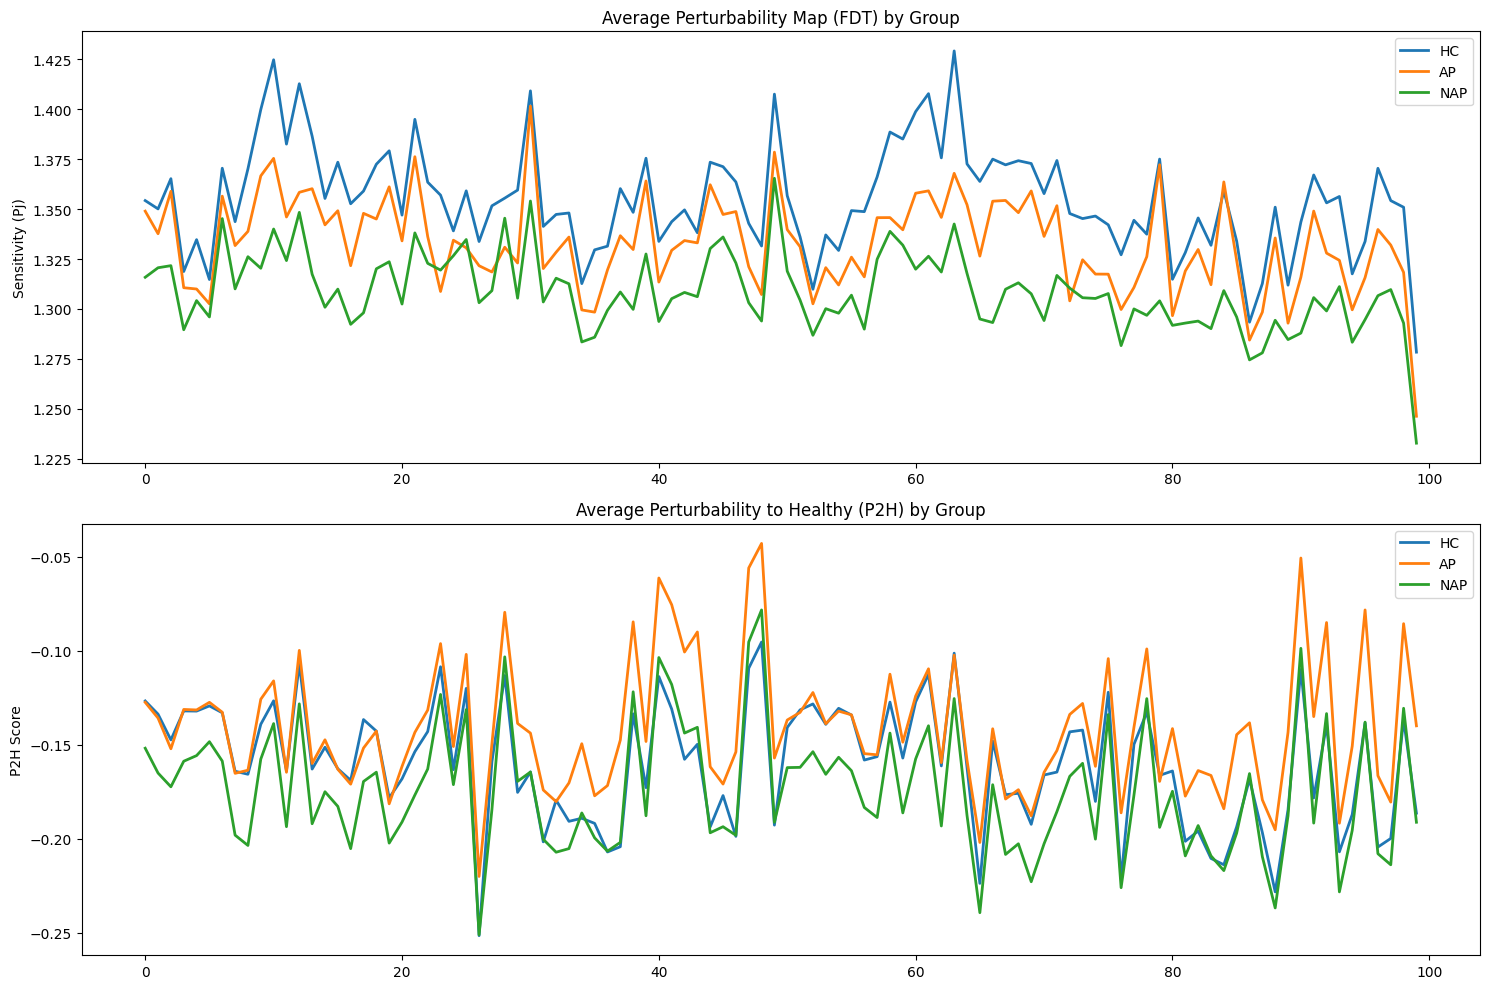

In [67]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(2, 1, figsize=(15, 10))

# 1. Plot Perturbability (FDT) Group Comparison
for group in ['HC', 'AP', 'NAP']:
    ax[0].plot(group_p_avg[group], label=group, linewidth=2)
ax[0].set_title("Average Perturbability Map (FDT) by Group")
ax[0].set_ylabel("Sensitivity (Pj)")
ax[0].legend()

# 2. Plot P2H (Healing Potential) Group Comparison
for group in ['HC', 'AP', 'NAP']:
    ax[1].plot(group_p2h_avg[group], label=group, linewidth=2)
ax[1].set_title("Average Perturbability to Healthy (P2H) by Group")
ax[1].set_ylabel("P2H Score")
ax[1].legend()

plt.tight_layout()
plt.show()

Perturbabilty tells us how sensitive each part of the brain is.

---

-  We see that HC have higher values of perturbability:
A healthy brain is highly "responsive." Because it is integrated and flexible, a small perturbation in one region can propagate efficiently across the whole network. This high sensitivity is what $P_j$ metric is picking up—it shows the brain has a high dynamic range.

-  AP/NAP (Lower Peaks): In psychosis or brain injury, the system often moves away from this critical point. The brain becomes "rigid" or "decoupled." Even if you perturb a region, the signal doesn't spread as effectively because the underlying "conductor" (the GEC) is disrupted.

p2h tells us how different brain states react to "noise" and how much they resist or succumb to change.

---
-  p2h always negative: Basically $\text{Sim}(perturbed) < \text{Sim}(baseline)$. Perturbing the brain—essentially adding noise—is almost always "destructive" to the delicate functional patterns that define a healthy-like state.

-  p2h is "higher" (closer to zero) in Acute Psychosis (AP), it means the perturbation is doing less damage to the similarity than it does in other groups.

-  the NAP subjects have the lowest (most negative) values, their brains are hypersensitive to the perturbation. A small "kick" at node $j$ causes a massive drop in similarity to the healthy state.


## Clinical Score analysis

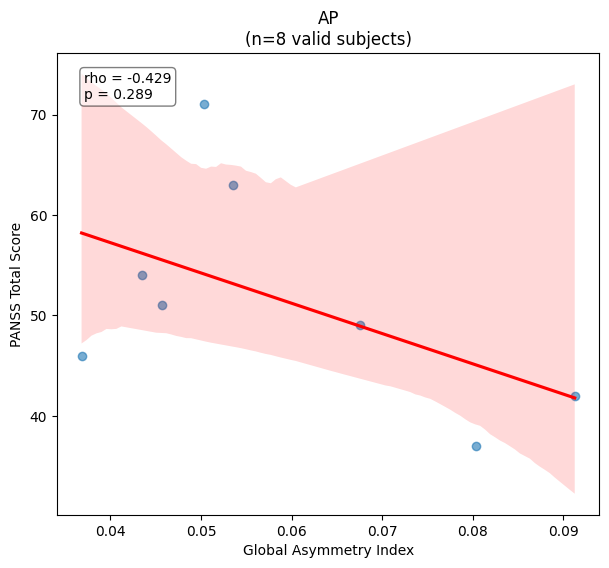

In [30]:
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
import seaborn as sns

def study_global_flow_severity(group_name, global_asym_list, panss_scores, n_subjects=10):
    # 1. Slice the data to the number of subjects we've processed
    x = np.array(global_asym_list[:n_subjects])
    y = np.array(panss_scores[:n_subjects])
    
    # 2. Create a mask: Only keep indices where BOTH x and y are NOT NaN
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_clean = x[mask]
    y_clean = y[mask]
    
    # Check if we have enough data points left to correlate
    if len(x_clean) < 3:
        print(f"Warning: Not enough valid data points for {group_name} (n={len(x_clean)})")
        return np.nan, np.nan

    # 3. Compute Spearman Correlation on clean data
    r_val, p_val = spearmanr(x_clean, y_clean)
    
    # 4. Plotting
    plt.figure(figsize=(7, 6))
    # regplot handles NaNs for plotting, but it's safer to use clean data
    sns.regplot(x=x_clean, y=y_clean, scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
    
    plt.title(f"{group_name}\n(n={len(x_clean)} valid subjects)")
    plt.xlabel("Global Asymmetry Index")
    plt.ylabel("PANSS Total Score")
    
    plt.annotate(f'rho = {r_val:.3f}\np = {p_val:.3f}', 
                 xy=(0.05, 0.9), xycoords='axes fraction', 
                 bbox=dict(boxstyle="round", fc="w", alpha=0.5))
    plt.show()
    
    return r_val, p_val

# Execute for AP
r_ap, p_ap = study_global_flow_severity('AP', global_asym_index['AP'], panss_AP)

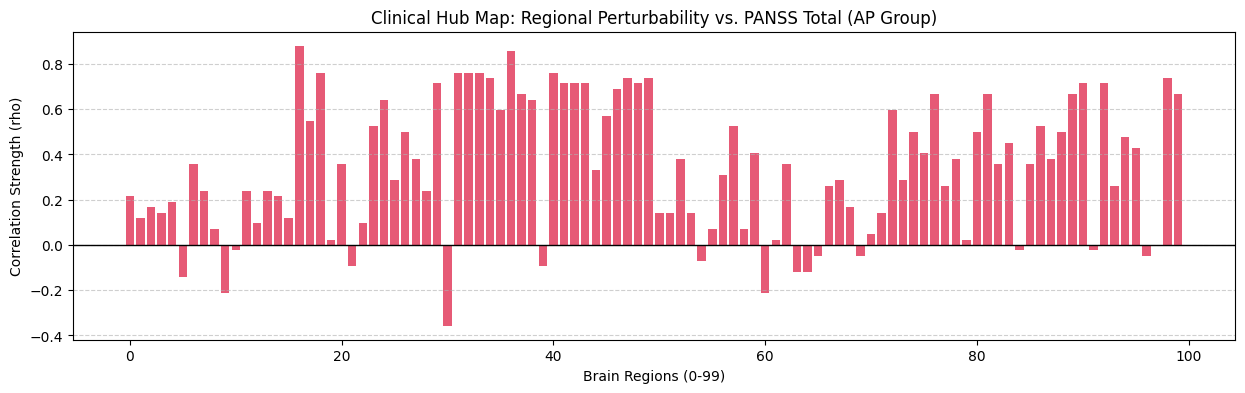

Top Clinical Hubs (Regions): [33 36 16]


In [28]:
def find_clinical_hubs(p_maps_group, panss_scores, n_subjects=10):
    # Convert dict to matrix (Subjects, Regions) and slice
    p_matrix = np.array(list(p_maps_group.values()))[:n_subjects]
    scores = np.array(panss_scores)[:n_subjects]
    
    n_regions = p_matrix.shape[1]
    region_rhos = np.zeros(n_regions)
    region_ps = np.zeros(n_regions)
    
    for j in range(n_regions):
        # Local regional perturbability
        x = p_matrix[:, j]
        y = scores
        
        # Mask out NaNs for this specific region-score pair
        mask = ~np.isnan(x) & ~np.isnan(y)
        
        if np.sum(mask) > 3:
            rho, p = spearmanr(x[mask], y[mask])
            region_rhos[j] = rho
            region_ps[j] = p
        else:
            region_rhos[j], region_ps[j] = np.nan, np.nan
            
    return region_rhos, region_ps
# Run for AP group
ap_hubs_rho, ap_hubs_p = find_clinical_hubs(p_maps['AP'], panss_AP)

# Plot the "Clinical Impact Map"
plt.figure(figsize=(15, 4))
plt.bar(range(100), ap_hubs_rho, color='crimson', alpha=0.7)
plt.axhline(0, color='black', linewidth=1)
plt.title("Clinical Hub Map: Regional Perturbability vs. PANSS Total (AP Group)")
plt.xlabel("Brain Regions (0-99)")
plt.ylabel("Correlation Strength (rho)")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.show()

# Find the top 3 most significant hubs
top_hubs = np.argsort(np.abs(ap_hubs_rho))[-3:]
print(f"Top Clinical Hubs (Regions): {top_hubs}")

In [ ]:
import pandas as pd
import numpy as np
from nilearn import datasets
from nilearn.plotting import find_parcellation_cut_coords

def get_schaefer_100_mapping():
    # Fetch the official 100 regions mapped to 7 networks
    atlas = datasets.fetch_atlas_schaefer_2018(n_rois=100, yeo_networks=7)
    
    # 1. Decode labels safely from bytes
    raw_labels = [l.decode('utf-8') if isinstance(l, bytes) else str(l) for l in atlas.labels]
    
    # 2. FIX: Remove the 'Background' label so we are left with exactly 100 regions
    labels = [l for l in raw_labels if l.lower() != 'background']
    
    # 3. Calculate spatial centroids (Returns exactly 100 coordinates)
    print("Calculating brain region MNI coordinates...")
    coordinates = find_parcellation_cut_coords(atlas.maps)
    
    mapping_data = []
    
    # 4. ZIP them together so they perfectly align!
    for idx, (label, coord) in enumerate(zip(labels, coordinates)):
        parts = label.split('_')
        
        # Protect against unexpected label formats
        if len(parts) < 4:
            continue
            
        hemisphere = parts[1]       # 'LH' (Left) or 'RH' (Right)
        network = parts[2]          # 'Vis', 'SomMot', 'DorsAttn', etc.
        
        # Clean up the network names
        network_clean = {
            'Vis': 'Visual',
            'SomMot': 'Somatomotor',
            'DorsAttn': 'Dorsal Attention',
            'SalVentAttn': 'Salience/Ventral Attn',
            'Limbic': 'Limbic',
            'Cont': 'Executive Control',
            'Default': 'Default Mode (DMN)'
        }.get(network, network)
        
        mapping_data.append({
            'region_idx': idx,
            'hemisphere': 'Left' if hemisphere == 'LH' else 'Right',
            'macro_network': network_clean,
            'mni_x': coord[0],
            'mni_y': coord[1],
            'mni_z': coord[2],
            'original_label': label
        })
        
    return pd.DataFrame(mapping_data)

# Re-create the master lookup table safely
df_lookup = get_schaefer_100_mapping()

In [39]:
df_lookup.macro_network.value_counts()

macro_network
Default Mode (DMN)       24
Visual                   17
Dorsal Attention         15
Somatomotor              14
Executive Control        13
Salience/Ventral Attn    12
Limbic                    5
Name: count, dtype: int64